# PRISM — Phase 1: Data Understanding & Profiling
**Course:** Data Science and Analytics (CSE0521) · **Student:** Vikash Chauhan (BETN1CS24092)

AI tools were used as support only; every output below was checked by the student. Personal identifiers are never displayed.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from src.config import RANDOM_STATE, PII_COLS
from src.data_loading import load_raw, overview, stratified_sample
from src.profiling import quality_flags, run_sweetviz
from src import eda_plots as P
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
df = load_raw()

## 1. Shape, dtypes, missing values, duplicates, class balance

In [2]:
info = overview(df)
for k, v in info.items(): print(f'{k:22s}: {v}')

shape                 : (500000, 32)
dtypes                : {'int64': 13, 'str': 12, 'float64': 7}
missing_total         : 0
missing_by_col        : {}
duplicate_rows        : 0
duplicate_loan_id     : 0
duplicate_borrower_id : 0
class_counts          : {0: 467647, 1: 32353}
class_pct             : {0: 93.529, 1: 6.471}


Note: we print counts only. `df.head()` is deliberately NOT shown because it would display names (PII).

In [3]:
df.drop(columns=PII_COLS).describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,500000.0,37.130,9.655,19.000,30.000,37.000,44.000,65.000
latitude,500000.0,22.336,5.401,7.179,19.389,23.477,26.470,34.693
longitude,500000.0,79.850,4.887,68.105,76.032,79.312,83.392,96.314
household_size,500000.0,4.200,1.788,1.000,3.000,4.000,5.000,12.000
monthly_income,500000.0,11486.736,6017.044,3000.000,7300.000,10200.000,14100.000,80000.000
existing_monthly_debt,500000.0,2502.248,2229.275,0.000,980.000,1890.000,3330.000,40190.000
savings_balance,500000.0,12405.702,14319.672,0.000,3430.000,7880.000,16100.000,391230.000
loan_amount,500000.0,60243.196,41680.239,5000.000,31000.000,50000.000,78000.000,300000.000
tenure_months,500000.0,17.643,8.263,6.000,12.000,18.000,24.000,36.000
interest_rate_pct,500000.0,21.004,3.486,12.000,18.630,21.000,23.360,32.000


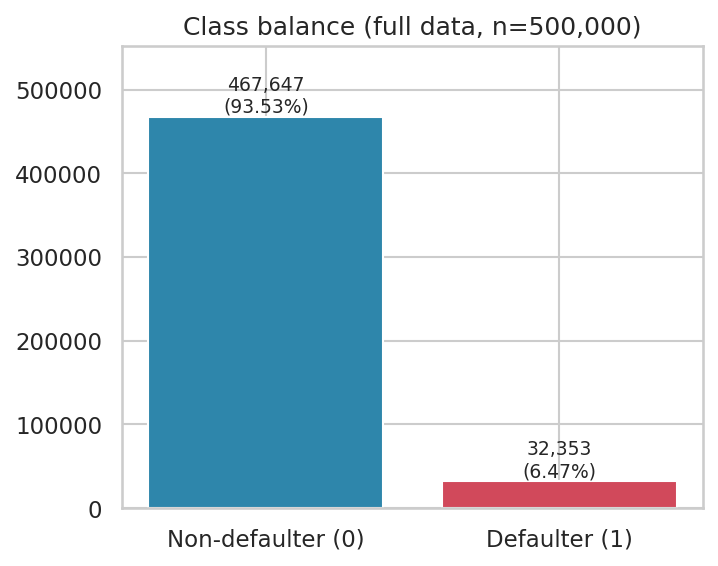

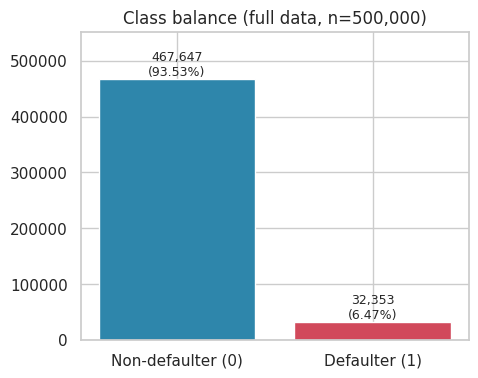

In [4]:
display(Image(P.plot_class_balance(df)))

**Reading:** about 6.5% defaulters (1 in 15). A model that predicts 'no default' for everyone gets ~93.5% accuracy but catches zero defaulters, which is why accuracy is not used in this project.

## 2. Data-quality audit

In [5]:
qf = quality_flags(df); qf

,rule,rows,pct,default_rate_pct
0,emi_to_income > 1 (EMI > monthly income),22383,4.477,28.35
1,debt_to_income > 1 (total obligations > income),56268,11.254,19.74
2,prev_defaults > prev_loans_count,0,0.000,NaN
3,late payments but zero days past due,6,0.001,16.67
4,credit_score < 350,10,0.002,60.00
5,credit_score > 850,546,0.109,1.65
6,savings_balance == 0,67,0.013,8.96
7,existing_monthly_debt == 0,50,0.010,0.00
8,household_size >= 10,2862,0.572,7.20
9,"monthly_income >= 50,000",328,0.066,6.40


**Decisions (and why):**
| Finding | Decision | Reason |
|---|---|---|
| No missing values, no duplicates | nothing to impute | the file is complete |
| `emi_to_income > 1` (4.48%, default rate 28%) | **keep**, add flag `emi_gt_income` | impossible to repay from income alone, yet it is real risk signal; deleting it would hide the riskiest borrowers |
| `debt_to_income > 1` (11.25%) | **keep** | `debt_to_income` = (existing debt + new EMI) / income, so >1 is plausible overborrowing |
| Right-skewed money columns (income, savings, loan) | winsorise at 1st/99th percentile **inside the pipeline** | stops a few extreme rows dominating scaling/linear models; tree models are unaffected |
| `credit_score` <350 or >850 (556 rows) | keep, clip in pipeline | rare, in valid 300-900 range |
| `late_payments_12m`>0 but days_past_due = 0 (6 rows) | keep | negligible, likely rounding |
| lat/long | keep | each state forms a tight cluster (std ~0.9 degrees), so coordinates are consistent with state |

## 3. Ratio consistency (are the pre-computed ratios correct?)

In [6]:
import numpy as np
r = lambda a,b: float((a-b).abs().max())
print('debt_to_income  vs (existing_debt + EMI)/income :', round(r(df.debt_to_income, (df.existing_monthly_debt+df.monthly_emi)/df.monthly_income),4))
print('loan_to_income  vs loan/(12*income)             :', round(r(df.loan_to_income, df.loan_amount/(12*df.monthly_income)),4))
print('emi_to_income   vs EMI/income                   :', round(r(df.emi_to_income, df.monthly_emi/df.monthly_income),4))

debt_to_income  vs (existing_debt + EMI)/income : 0.0018
loan_to_income  vs loan/(12*income)             : 0.0
emi_to_income   vs EMI/income                   : 0.0002


All three ratios reproduce from raw columns (differences are rounding only). Important for viva: `debt_to_income` already *includes* the new EMI.

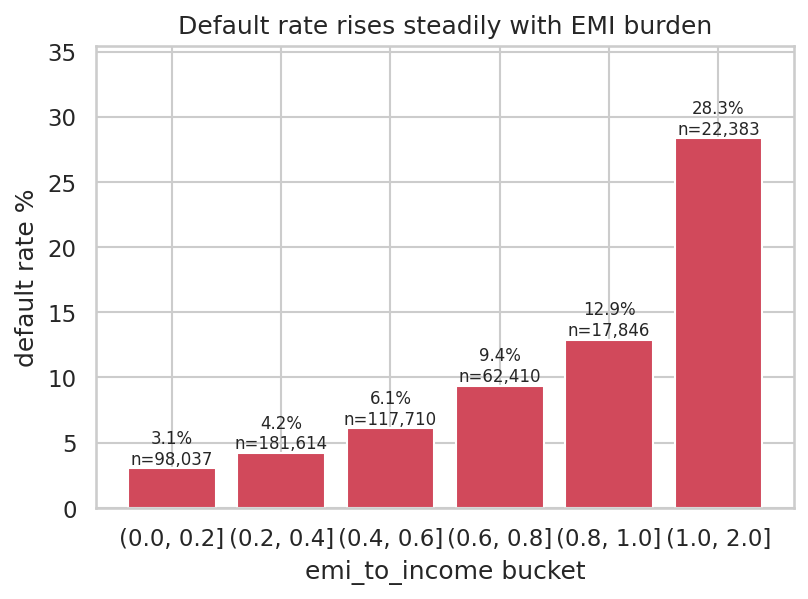

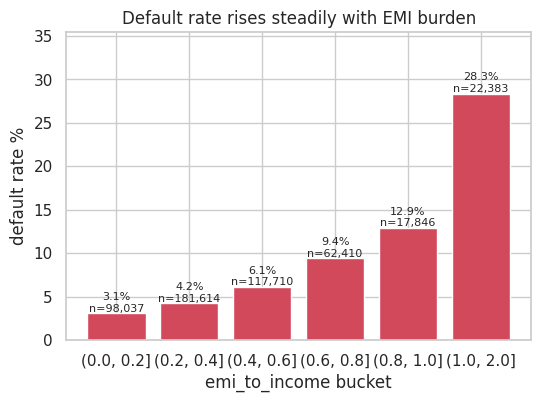

In [7]:
display(Image(P.plot_ratio_buckets(df)))

## 4. Automated profiling on a stratified 50,000-row sample

In [8]:
sample = stratified_sample(df, 50_000)          # same default rate as full data
print('sample default rate %.3f%% vs full %.3f%%' % (sample.default.mean()*100, df.default.mean()*100))
path = run_sweetviz(sample)                       # PII columns removed inside the function
print('Sweetviz report saved to', path)

sample default rate 6.470% vs full 6.471%


                                             |          | [  0%]   00:00 -> (? left)

[Summarizing dataframe]                      |          | [  0%]   00:00 -> (? left)

Feature: default (TARGET)                    |▎         | [  3%]   00:00 -> (00:01 left)

Feature: default (TARGET)                    |▋         | [  7%]   00:00 -> (00:01 left)

Feature: gender                              |▋         | [  7%]   00:00 -> (00:01 left)

... (69 outputs left out)

Done! Use 'show' commands to display/save.   |          | [  0%]   00:01 -> (? left)

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)

Report /home/claude/prism/reports/profiling/sweetviz_report.html was generated.
Sweetviz report saved to /home/claude/prism/reports/profiling/sweetviz_report.html


**AutoViz** could not run: its current release is incompatible with pandas 3 (`applymap` was removed). Instead, the charts below do the same job (distributions, class-wise comparison).

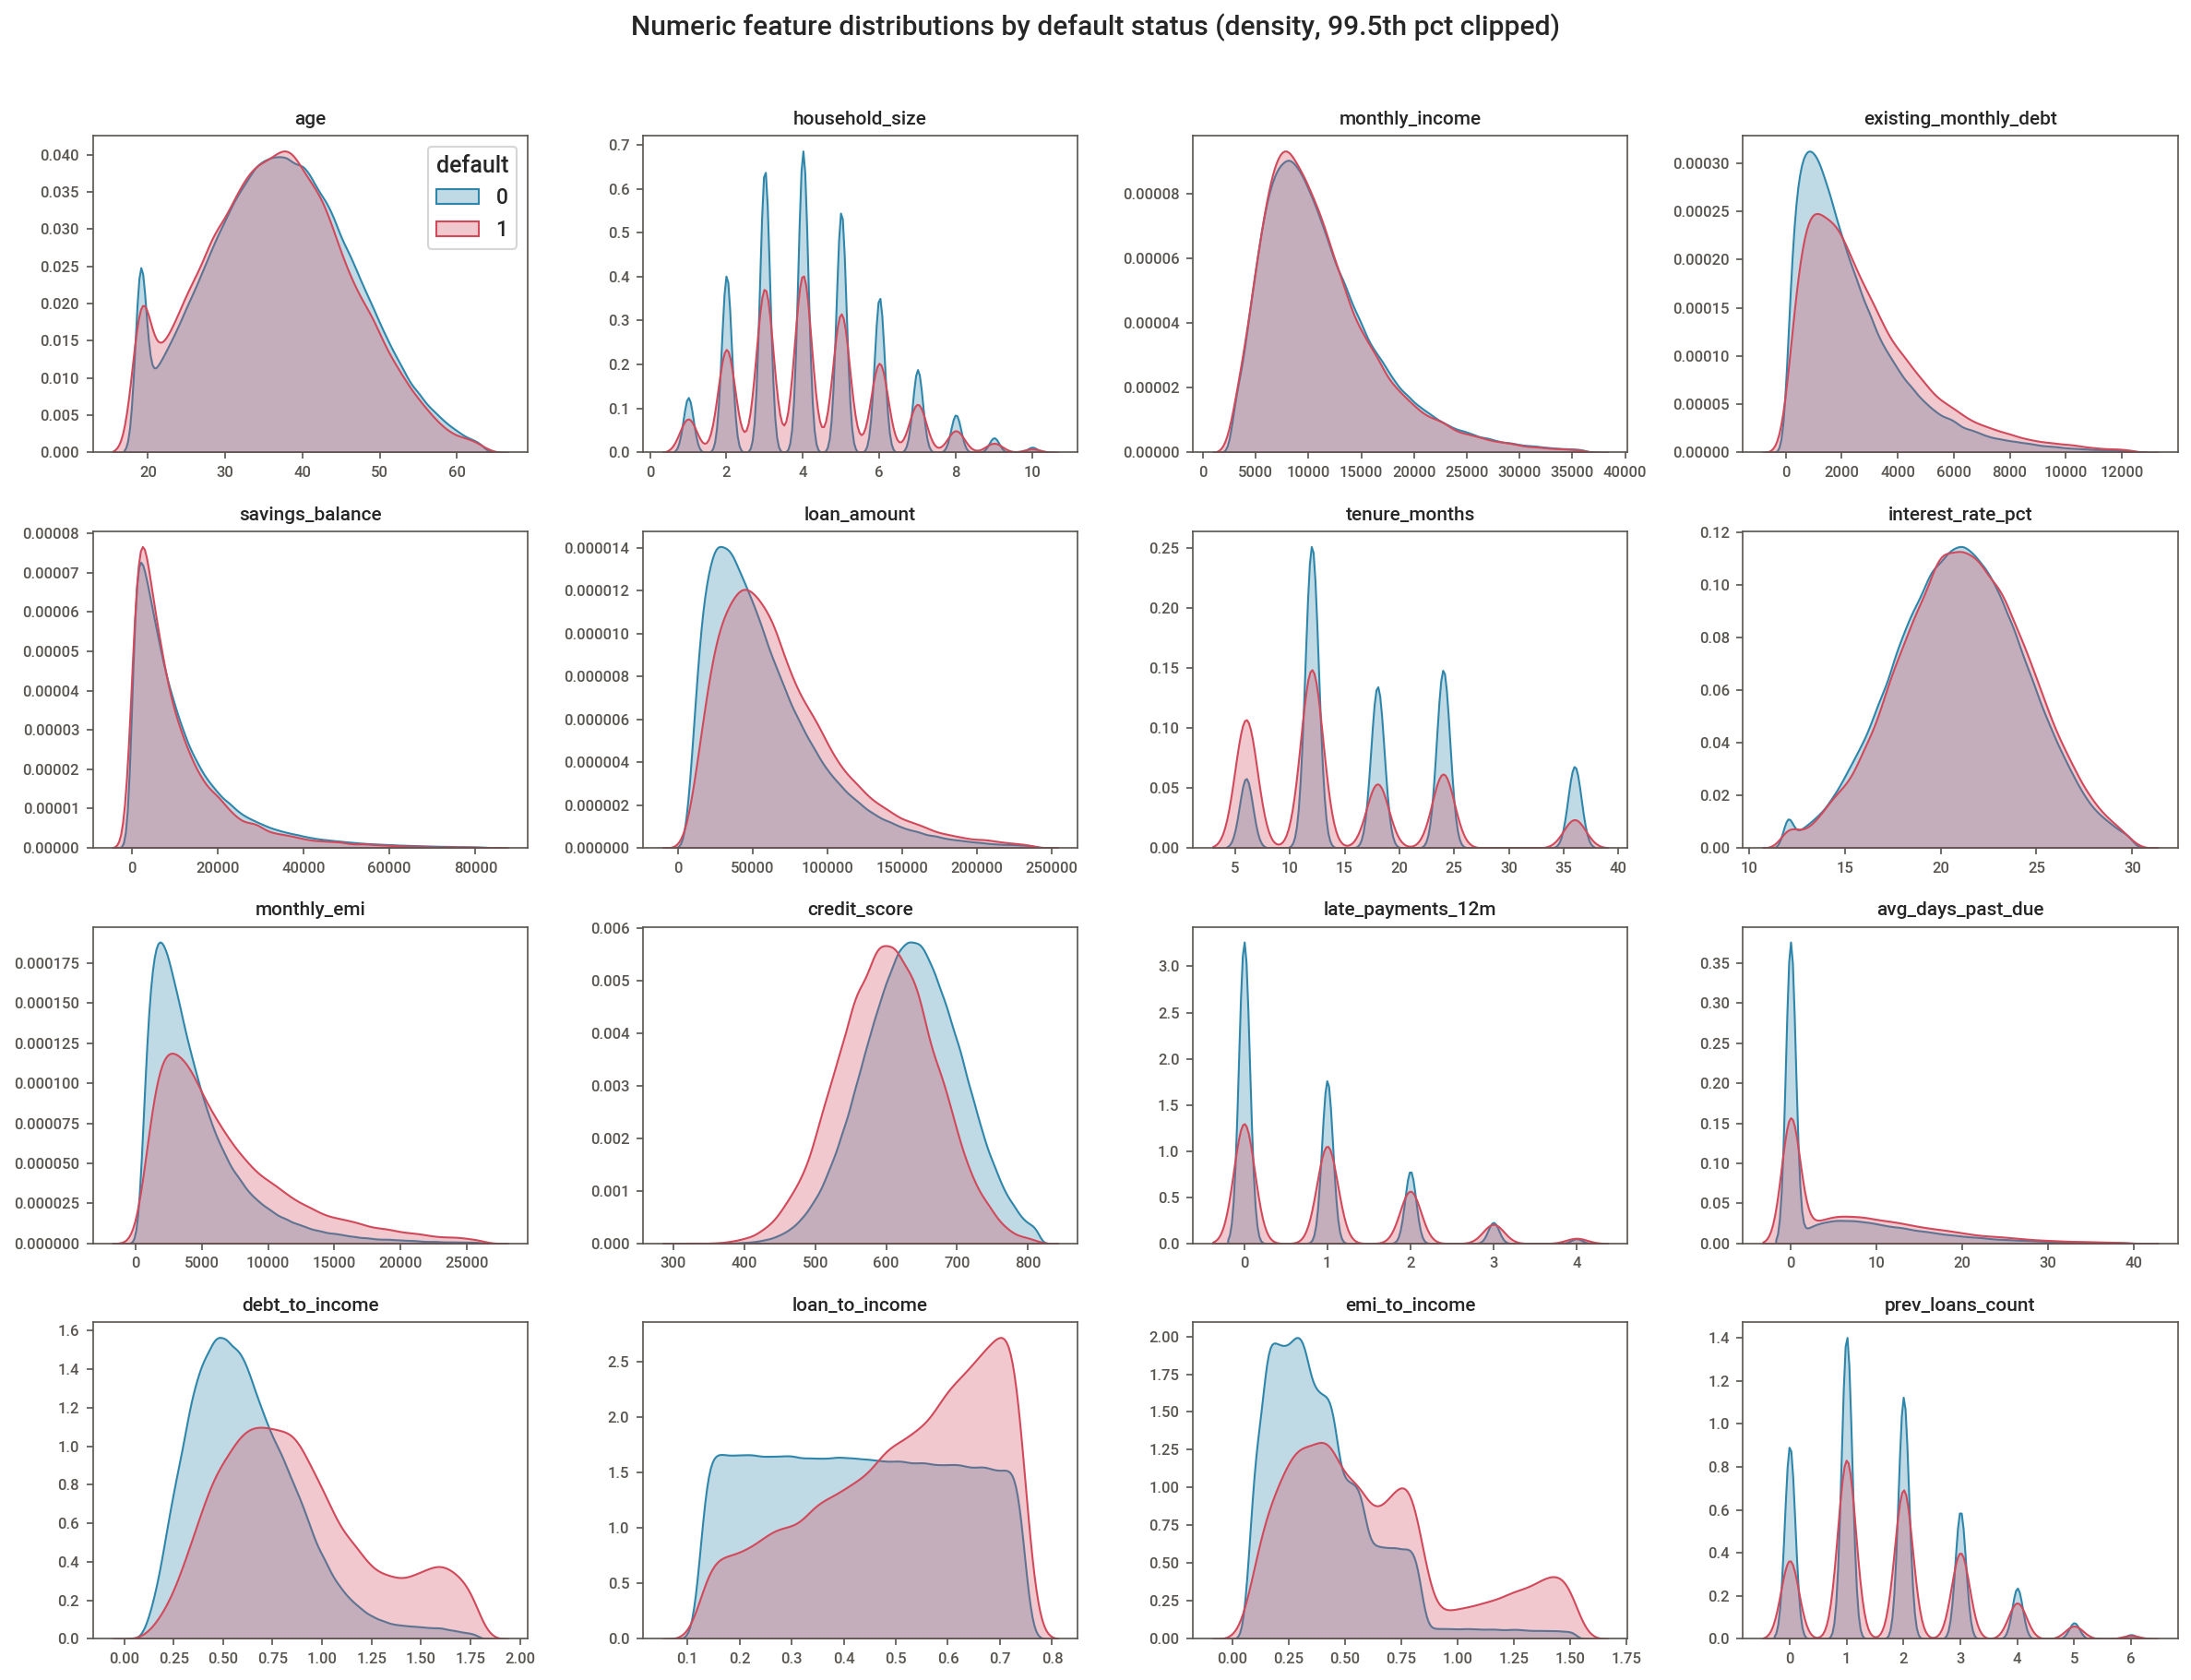

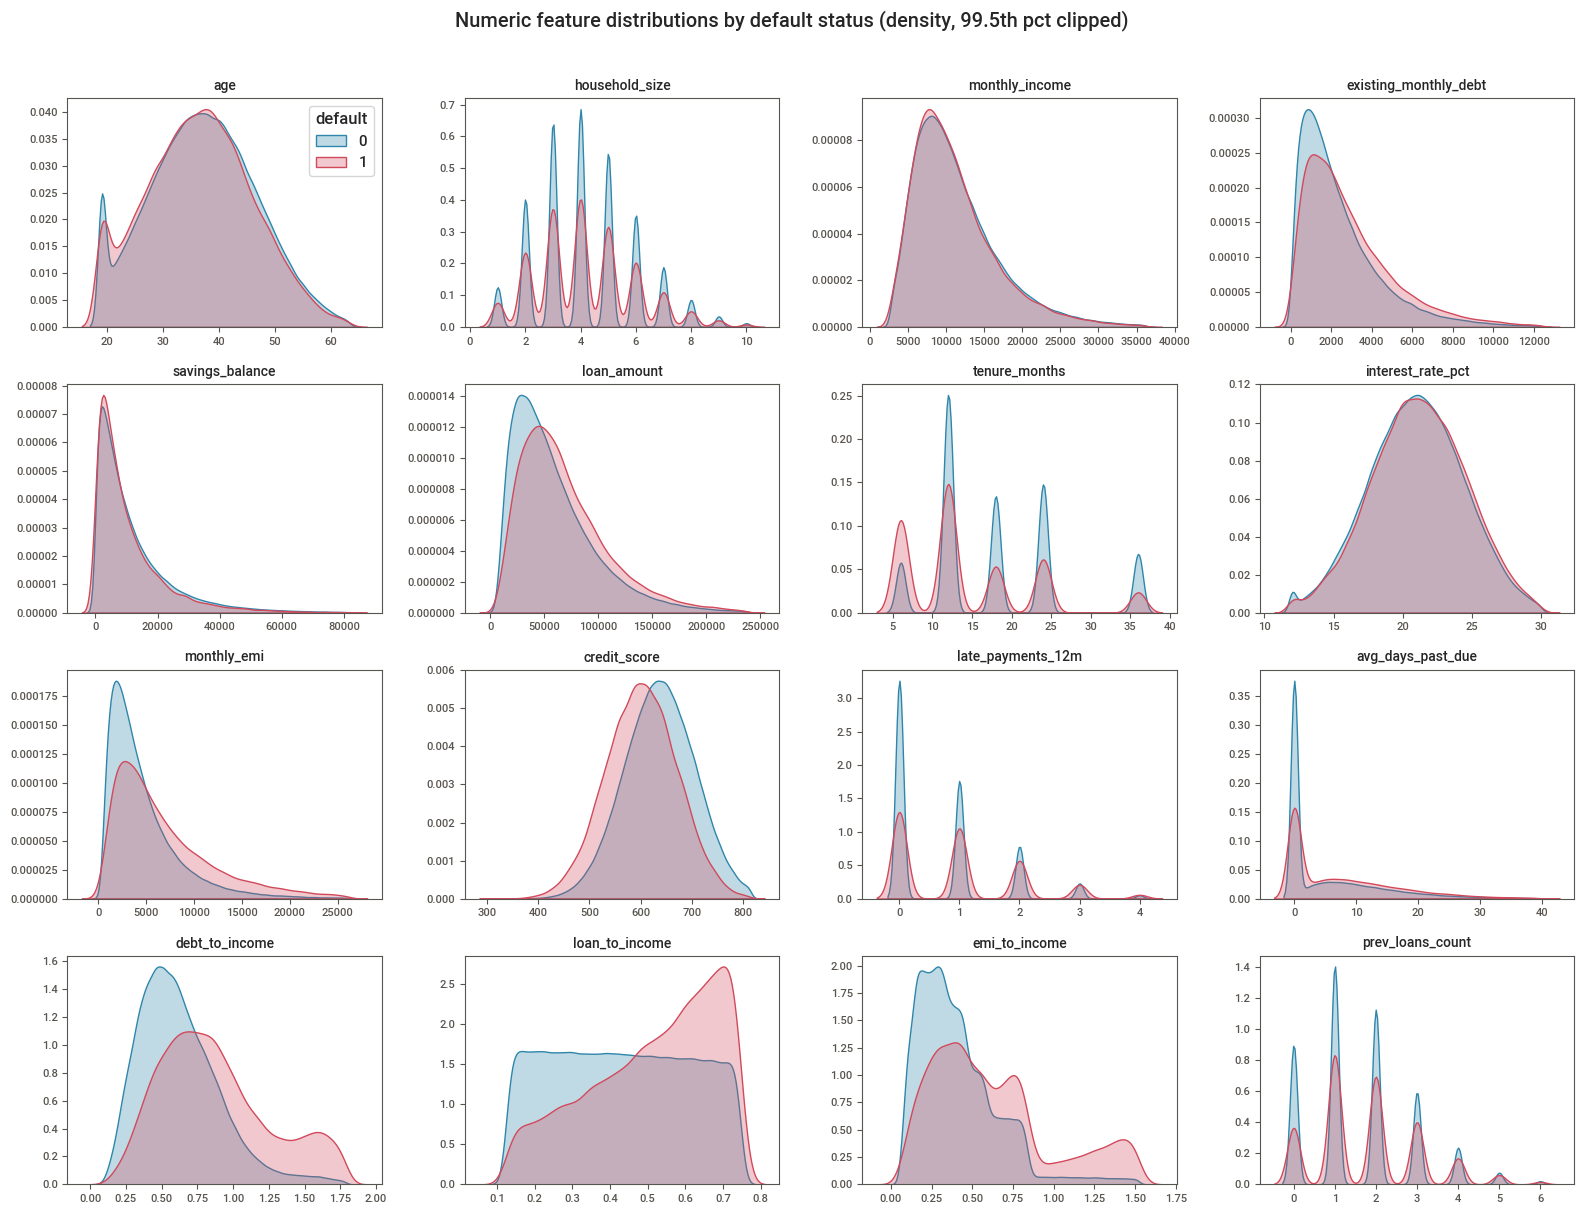

In [9]:
num = ['age','household_size','monthly_income','existing_monthly_debt','savings_balance','loan_amount','tenure_months',
       'interest_rate_pct','monthly_emi','credit_score','late_payments_12m','avg_days_past_due','debt_to_income','loan_to_income','emi_to_income','prev_loans_count']
display(Image(P.plot_numeric_by_class(df, num)))

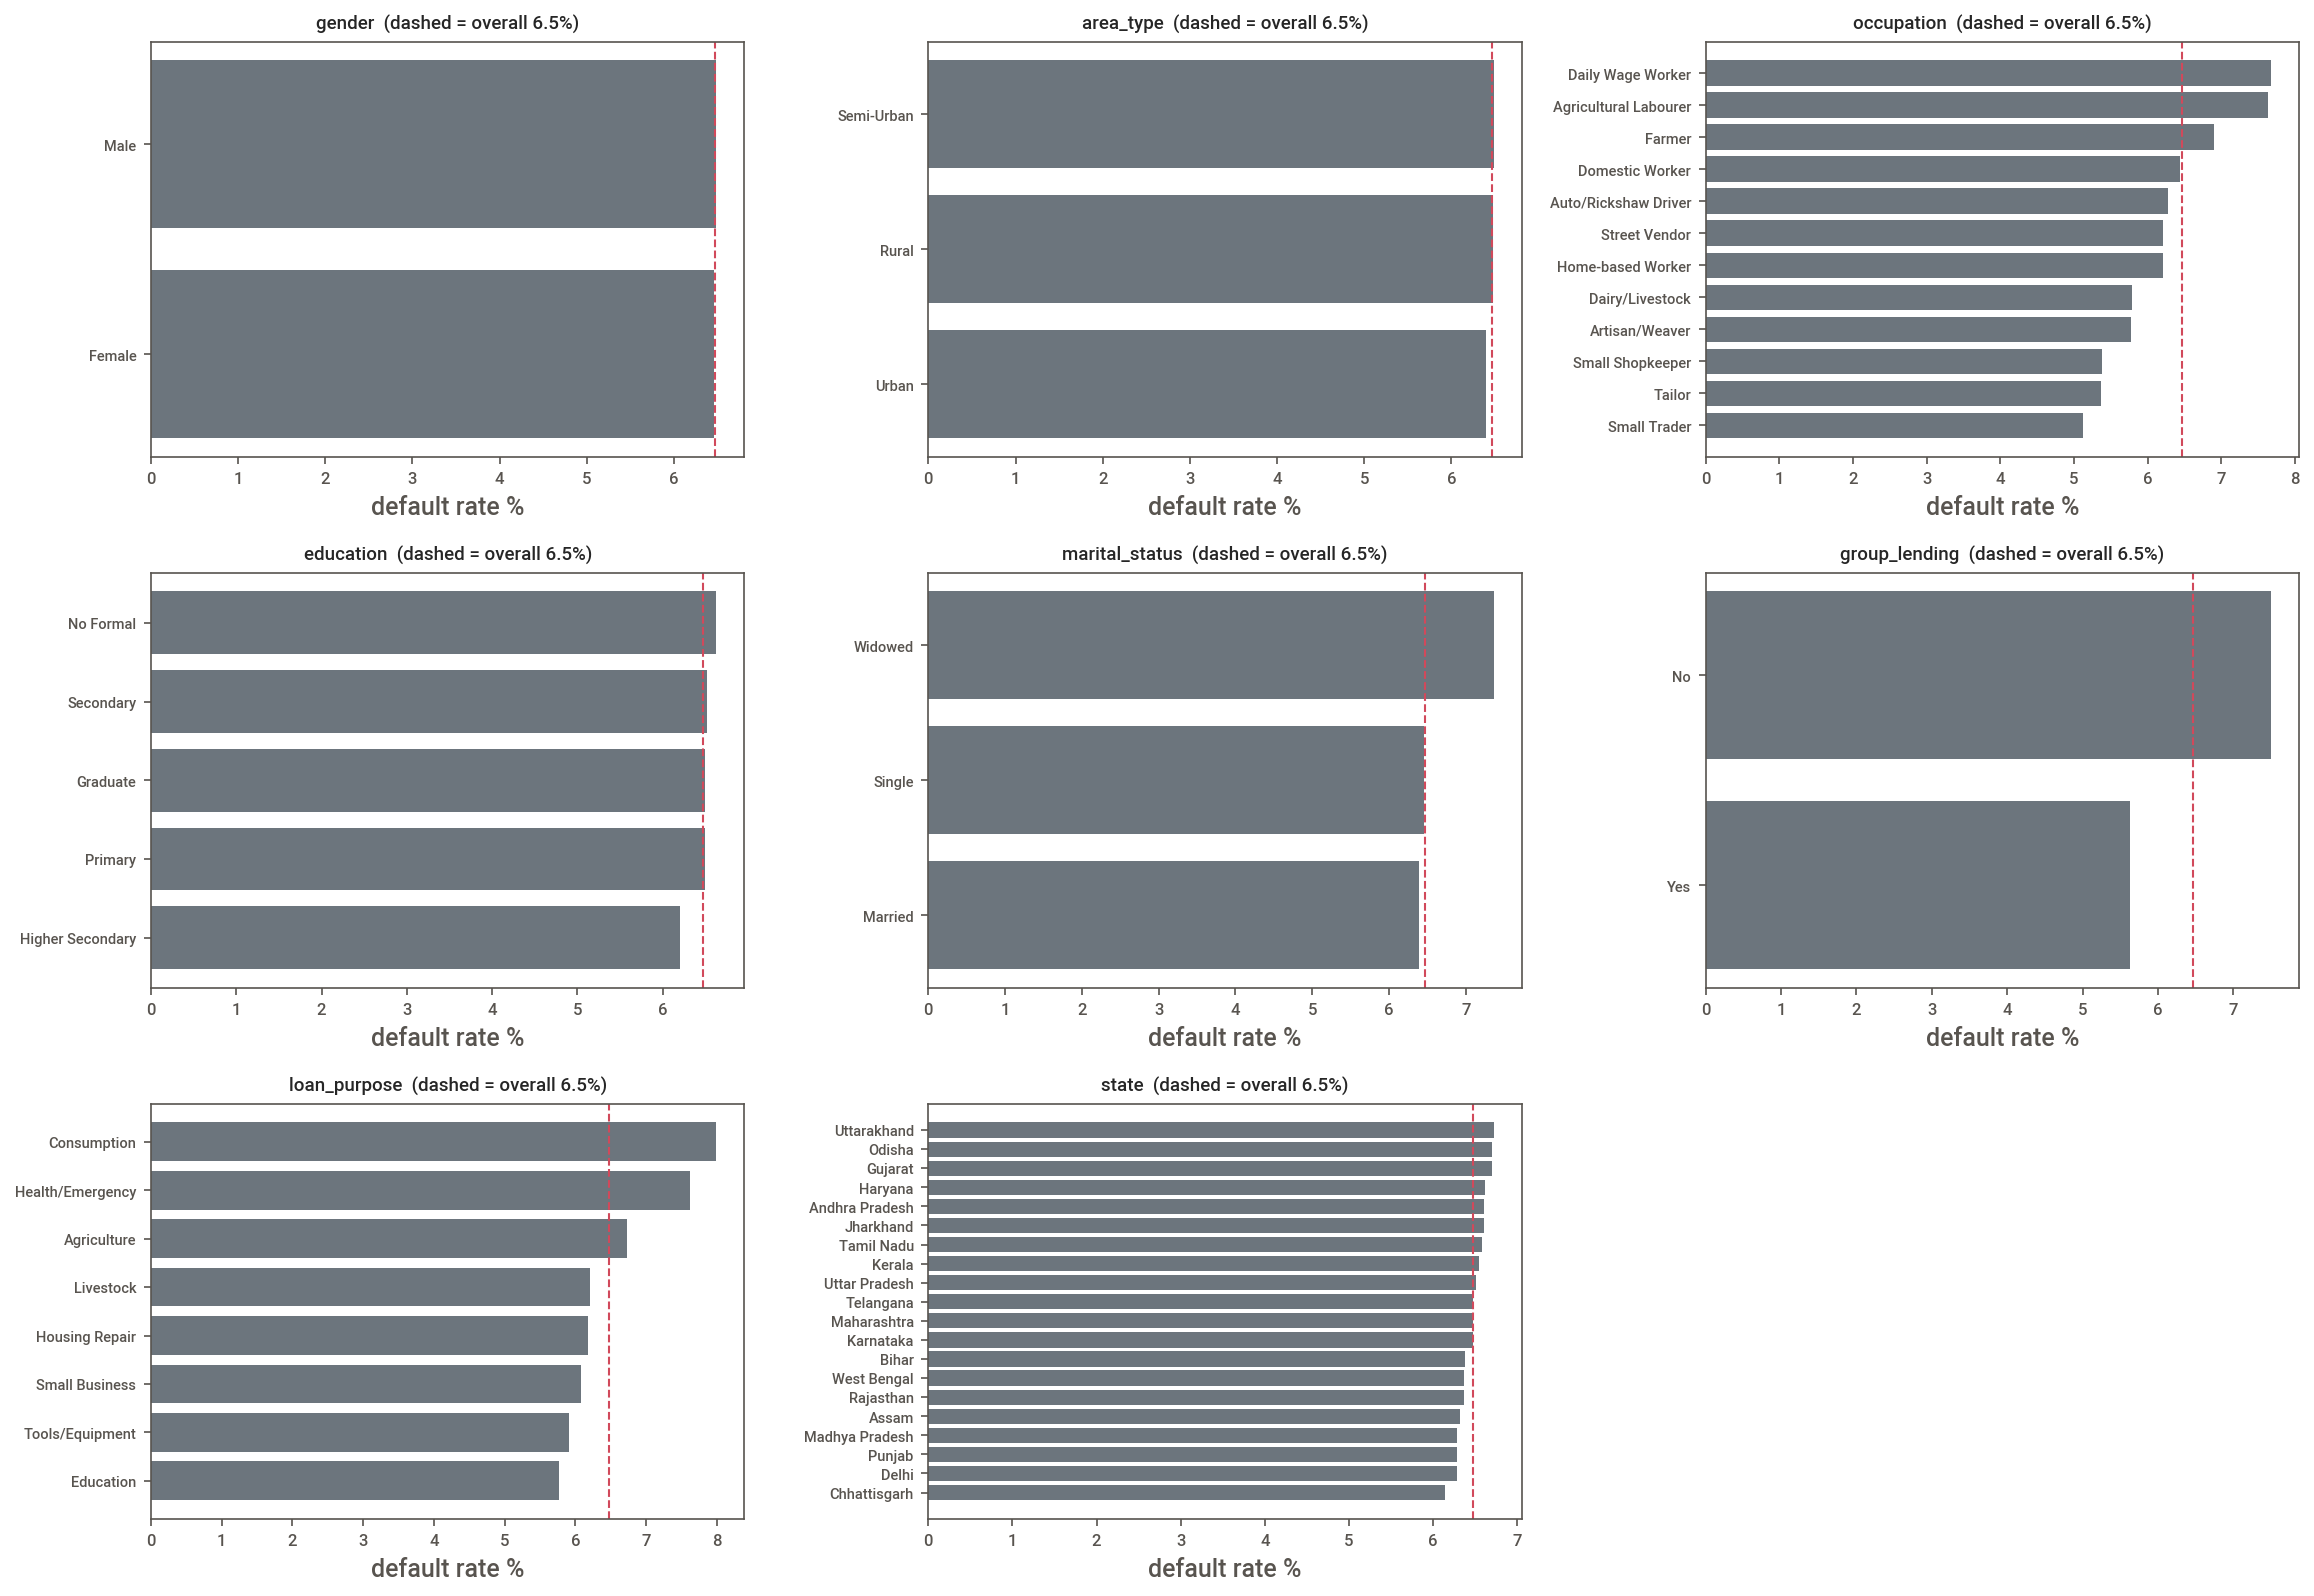

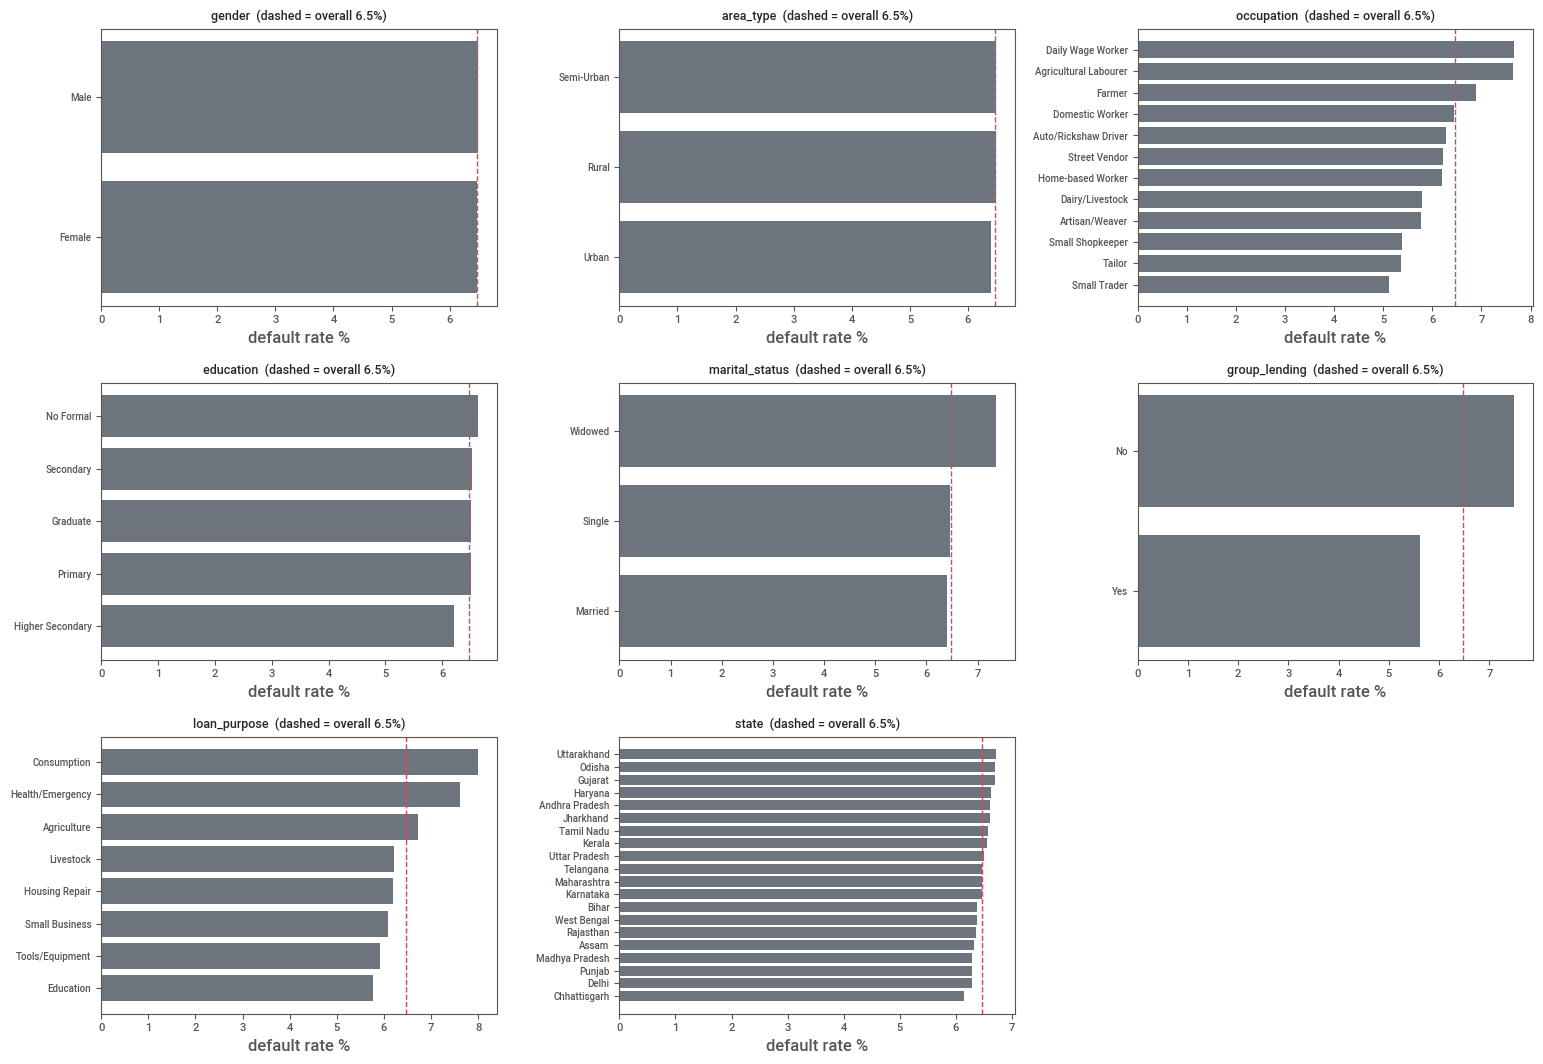

In [10]:
cat = ['gender','area_type','occupation','education','marital_status','group_lending','loan_purpose','state']
display(Image(P.plot_default_rate_by_cat(df, cat)))

## 5. Phase-1 takeaways
* Strongest raw signals: `debt_to_income`, `emi_to_income`, `monthly_emi`, `credit_score` (negative), `tenure_months` (6-month loans default at 17.6% vs ~4% for 36-month).
* Weak/no signal: gender, area_type, state, household_size, lat/long (default rates nearly identical). Good news for the fairness audit in Phase 6.
* Behavioural columns (`late_payments_12m`, `avg_days_past_due`) must be checked for leakage in Phase 4.